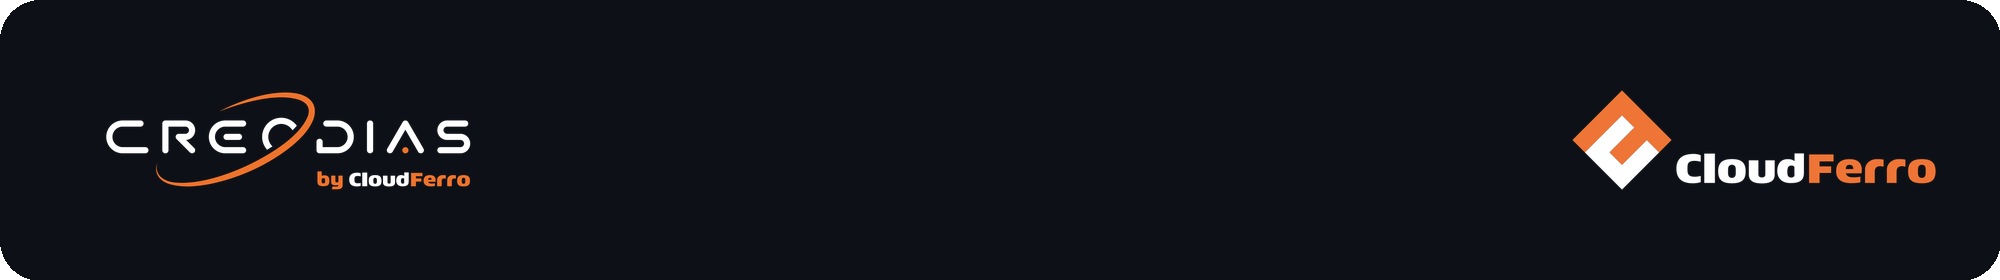


# EuroSAT: from pixels to predictions

Your first tour of the **geoAI-training** collection on CREODIAS. We explore one dataset, then teach three models to recognise what is on the ground, building each one step by step before using the library version:

| Model | Family | Sees |
|---|---|---|
| **Random Forest** | classic machine learning | 29 numbers per patch that we compute |
| **Support Vector Machine** | classic machine learning | the same 29 numbers |
| **Convolutional Neural Network** | deep learning | every pixel of every band |

Entry level: basic Python is enough. A few minutes with a GPU, plus about two minutes to copy the data the first time.

## The geoAI-training collection

`/eodata/geoAI-training/` holds ready-to-use training datasets for Earth observation, next to the raw satellite archive:

| Dataset | What it is | Typical use |
|---|---|---|
| **EuroSAT** | 27,000 Sentinel-2 patches, 10 land cover classes | classification, *this notebook* |
| **BigEarthNet** | about 549,000 Sentinel-1 + Sentinel-2 patches, multi-label | multi-label classification, radar + optical fusion |
| **SSL4EO** | 250,000 locations x 4 seasons, Sentinel-1/2 | self-supervised pre-training, seasonal change |
| **OLMOEarth** | Sentinel-1/2, Landsat, terrain, climate, land cover, canopy height | regression, segmentation, multi-modal models |
| **MMEarth** | multi-modal patches in HDF5 | multi-task learning |
| **MajorTOM** | global Sentinel-1/2, elevation, night lights | large-scale pre-training, cross-sensor tasks |
| **CloudSEN12** | Sentinel-2 with hand-labelled clouds | cloud masking |

The collection keeps growing. Here we start with the smallest and friendliest: **EuroSAT**.

## Before you start

Run on a CREODIAS virtual machine with `/eodata` mounted. You need numpy, matplotlib, scikit-learn, rasterio, tqdm and PyTorch. Without a GPU the notebook uses lighter settings by itself and finishes in under ten minutes on a 4-core VM.

## Setup

In [ ]:
# OPTIONAL: only if the imports below fail. Uncomment, run once, then restart the kernel.
# PyTorch must match the VM's CUDA version (`nvidia-smi`, top right). For CUDA 12.8:
#   pip install torch --index-url https://download.pytorch.org/whl/cu128
# import subprocess, sys
# subprocess.run([sys.executable, "-m", "pip", "install", "-q", "numpy", "matplotlib", "scikit-learn", "rasterio", "tqdm", "ipywidgets"], check=True)

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import rasterio

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")

### Helper functions

The next cell defines a few helpers: checking for a GPU, copying files from `/eodata` to local disk, and plot style. Run it; you do not need to read it to follow the tutorial (click it to expand if you are curious).

In [2]:
# Helper functions. Run this cell; reading it is optional.
import os
import shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from tqdm.auto import tqdm

plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})


def choose_settings(speed, full, light):
    """Use `full` settings on a GPU and `light` ones on CPU, unless speed forces one."""
    gpu = torch.cuda.is_available()
    mode = speed if speed in ("full", "light") else ("full" if gpu else "light")
    print("Running on:", f"GPU ({torch.cuda.get_device_name(0)})" if gpu else "CPU (no GPU found)")
    print("Settings:  ", mode + ("  (slow without a GPU!)" if mode == "full" and not gpu else ""))
    if not gpu and shutil.which("nvidia-smi"):
        print("Note: this VM has an NVIDIA GPU, but this PyTorch build cannot use it. Install the "
              "PyTorch build that matches the CUDA version shown by `nvidia-smi`.")
    return ("cuda" if gpu else "cpu"), dict(full if mode == "full" else light)


def notebook_folder():
    """Folder of this notebook file (VS Code and JupyterLab both tell the kernel where it is)."""
    for p in (globals().get("__vsc_ipynb_file__"), os.environ.get("JPY_SESSION_NAME")):
        if p and p.endswith(".ipynb") and Path(p).exists():
            return Path(p).resolve().parent
    return Path.cwd()


DATA_DIR = notebook_folder() / "geoai_data"     # local working copy of the data, next to this notebook


def copy_files(pairs, desc="Copying"):
    """Copy (source, destination) file pairs in parallel and return one True/False per pair.

    Files already on local disk are skipped, so running this again costs nothing.
    A file that fails is retried once; one that still fails is reported as False.
    """
    def present(p):
        return p.exists() and p.stat().st_size > 0

    def copy_one(pair):
        src, dst = pair
        dst.parent.mkdir(parents=True, exist_ok=True)
        tmp = dst.with_name(dst.name + ".part")
        for _ in range(2):
            try:
                shutil.copyfile(src, tmp)
                tmp.rename(dst)
                return
            except OSError:
                time.sleep(1)

    todo = [p for p in pairs if not present(p[1])]
    if todo:
        with ThreadPoolExecutor(16) as pool:   # the storage, not the VM, limits the speed
            list(tqdm(pool.map(copy_one, todo), total=len(todo), desc=desc))
    return [present(dst) for _, dst in pairs]


def storage_error(path):
    return RuntimeError(
        f"Could not copy anything from {path}. Is /eodata mounted? Try `ls {path}` in a terminal. "
        "The storage sometimes refuses requests for a few minutes: wait and run the cell again. "
        "Files already copied are kept.")


def clean_axes(*axes):
    """Image panels: no ticks, no frame."""
    for ax in np.ravel(axes):
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)


def label_line_ends(ax, x, ys, labels):
    """Labels at the right end of lines, nudged apart so they never overlap."""
    lo, hi = ax.get_ylim()
    order = np.argsort(ys)
    pos = np.array(ys, dtype=float)[order]
    for k in range(1, len(pos)):
        pos[k] = max(pos[k], pos[k - 1] + (hi - lo) * 0.045)
    for k, i in enumerate(order):
        ax.annotate(labels[i], (x, ys[i]), xytext=(x, pos[k]), va="center", fontsize=9,
                    color="#333333", annotation_clip=False)

### GPU or CPU?

With a GPU the notebook uses the full settings. Without one it picks lighter ones by itself: a slimmer network and one optional experiment skipped. You can force either by changing `speed` to `"full"` or `"light"`.

In [3]:
SEED = 42   # fixes every random choice, so a rerun gives the same numbers

DEVICE, SETTINGS = choose_settings(
    speed="auto",
    full=dict(cnn_width=32, cnn_epochs=25, data_experiment=True),
    light=dict(cnn_width=16, cnn_epochs=15, data_experiment=False),
)

Running on: GPU (NVIDIA L40S-48Q)
Settings:   full


## Meet the data

EuroSAT ([Helber et al., 2019](https://arxiv.org/abs/1709.00029)) holds Sentinel-2 patches from 34 European countries: **64 x 64 pixels at 10 m** (640 x 640 m), **13 spectral bands**, one of ten labels each. Files are laid out as `EuroSAT/<Class>/multispectral/MS_<Class>_<n>.tif`.

Only three of the 13 bands are colours your eyes see; the rest carry most of the useful information.

In [4]:
# Band order inside every EuroSAT file, with centre wavelength (nm) and what each band is good for.
BANDS = [
    ("B01",  443, "Coastal aerosol"),
    ("B02",  490, "Blue"),
    ("B03",  560, "Green"),
    ("B04",  665, "Red"),
    ("B05",  705, "Red edge 1"),
    ("B06",  740, "Red edge 2"),
    ("B07",  783, "Red edge 3"),
    ("B08",  842, "Near infrared (NIR)"),
    ("B09",  945, "Water vapour"),
    ("B10", 1375, "Cirrus"),
    ("B11", 1610, "Short-wave infrared 1 (SWIR)"),
    ("B12", 2190, "Short-wave infrared 2 (SWIR)"),
    ("B8A",  865, "Narrow NIR"),
]
BAND_NAMES = [b[0] for b in BANDS]
B = {name: i for i, name in enumerate(BAND_NAMES)}   # B["B04"] -> index of the red band

CLASS_SIZES = {
    "AnnualCrop": 3000, "Forest": 3000, "HerbaceousVegetation": 3000, "Highway": 2500,
    "Industrial": 2500, "Pasture": 2000, "PermanentCrop": 2500, "Residential": 3000,
    "River": 2500, "SeaLake": 3000,
}
CLASSES = list(CLASS_SIZES)

# One colour per class, picked to hint at what the class looks like. Plots that use
# them also print the class name, so colour is never the only clue.
CLASS_COLORS = {
    "AnnualCrop": "#eda100", "Forest": "#006400", "HerbaceousVegetation": "#8cc63f",
    "Highway": "#7f7f7f", "Industrial": "#e34948", "Pasture": "#1baf7a",
    "PermanentCrop": "#eb6834", "Residential": "#e87ba4", "River": "#2a78d6",
    "SeaLake": "#4a3aa7",
}
for code, wl, desc in BANDS:
    print(f"{code:>4}  {wl:>5} nm  {desc}")

 B01    443 nm  Coastal aerosol
 B02    490 nm  Blue
 B03    560 nm  Green
 B04    665 nm  Red
 B05    705 nm  Red edge 1
 B06    740 nm  Red edge 2
 B07    783 nm  Red edge 3
 B08    842 nm  Near infrared (NIR)
 B09    945 nm  Water vapour
 B10   1375 nm  Cirrus
 B11   1610 nm  Short-wave infrared 1 (SWIR)
 B12   2190 nm  Short-wave infrared 2 (SWIR)
 B8A    865 nm  Narrow NIR


## Getting the data

Opening thousands of small files on `/eodata` one by one is slow and occasionally fails, so we first **copy** 400 random patches per class (about 170 MB) to a `geoai_data` folder next to this notebook, then work on that copy. Later runs find the files already there.

In [5]:
EUROSAT = Path("/eodata/geoAI-training/EuroSAT")
LOCAL = DATA_DIR / "EuroSAT"
patches_per_class = 400

# Pick random patch numbers per class (the same ones on every run), then copy those files.
rng = np.random.default_rng(SEED)
wanted = [(c, n) for c, size in CLASS_SIZES.items()
          for n in rng.permutation(np.arange(1, size + 1))[:patches_per_class]]
pairs = [(EUROSAT / c / "multispectral" / f"MS_{c}_{n}.tif", LOCAL / c / f"MS_{c}_{n}.tif") for c, n in wanted]
copied = copy_files(pairs, "Copying EuroSAT patches")

files = {c: [] for c in CLASS_SIZES}
for (c, _), (_, local), ok in zip(wanted, pairs, copied):
    if ok:
        files[c].append(local)
if not any(files.values()):
    raise storage_error(EUROSAT)

# A class the storage would not serve right now is left out, so the notebook still runs end to end.
CLASSES = [c for c in CLASS_SIZES if len(files[c]) >= patches_per_class // 2]
for c in CLASS_SIZES:
    if c not in CLASSES:
        print(f"NOTE: {c} could not be copied right now and is left out. Run this cell again later.")
print(f"Ready: {sum(len(files[c]) for c in CLASSES)} patches in {len(CLASSES)} classes, in {LOCAL}")

Ready: 4000 patches in 10 classes, in /home/eouser/BA/geoai_tutorials/geoai_data/EuroSAT


### Reading the patches

Dividing the stored integers by 10,000 gives **reflectance**, the share of sunlight the surface reflects (0 to 1).

Note: Sentinel-2 products processed since January 2022 carry a +1000 offset, so there reflectance is `(value - 1000) / 10000`. EuroSAT dates from 2017, so a plain division is right here.

In [6]:
X, y = [], []
for ci, c in enumerate(CLASSES):
    for path in files[c]:
        with rasterio.open(path) as ds:
            X.append(ds.read())
        y.append(ci)
X = np.stack(X).astype(np.float32) / 10000.0     # reflectance
y = np.array(y)
print(f"Dataset: {X.shape[0]} patches, each {X.shape[1]} bands x {X.shape[2]} x {X.shape[3]} pixels")

Dataset: 4000 patches, each 13 bands x 64 x 64 pixels


## A first look

To show a patch on screen we pick three bands and send them to the red, green and blue channels of the display. Using the real red, green and blue bands (B04, B03, B02) gives a **true colour** image, close to what you would see from a plane.

Raw reflectance of land is low, mostly below 0.2, so the images are brightened before display.

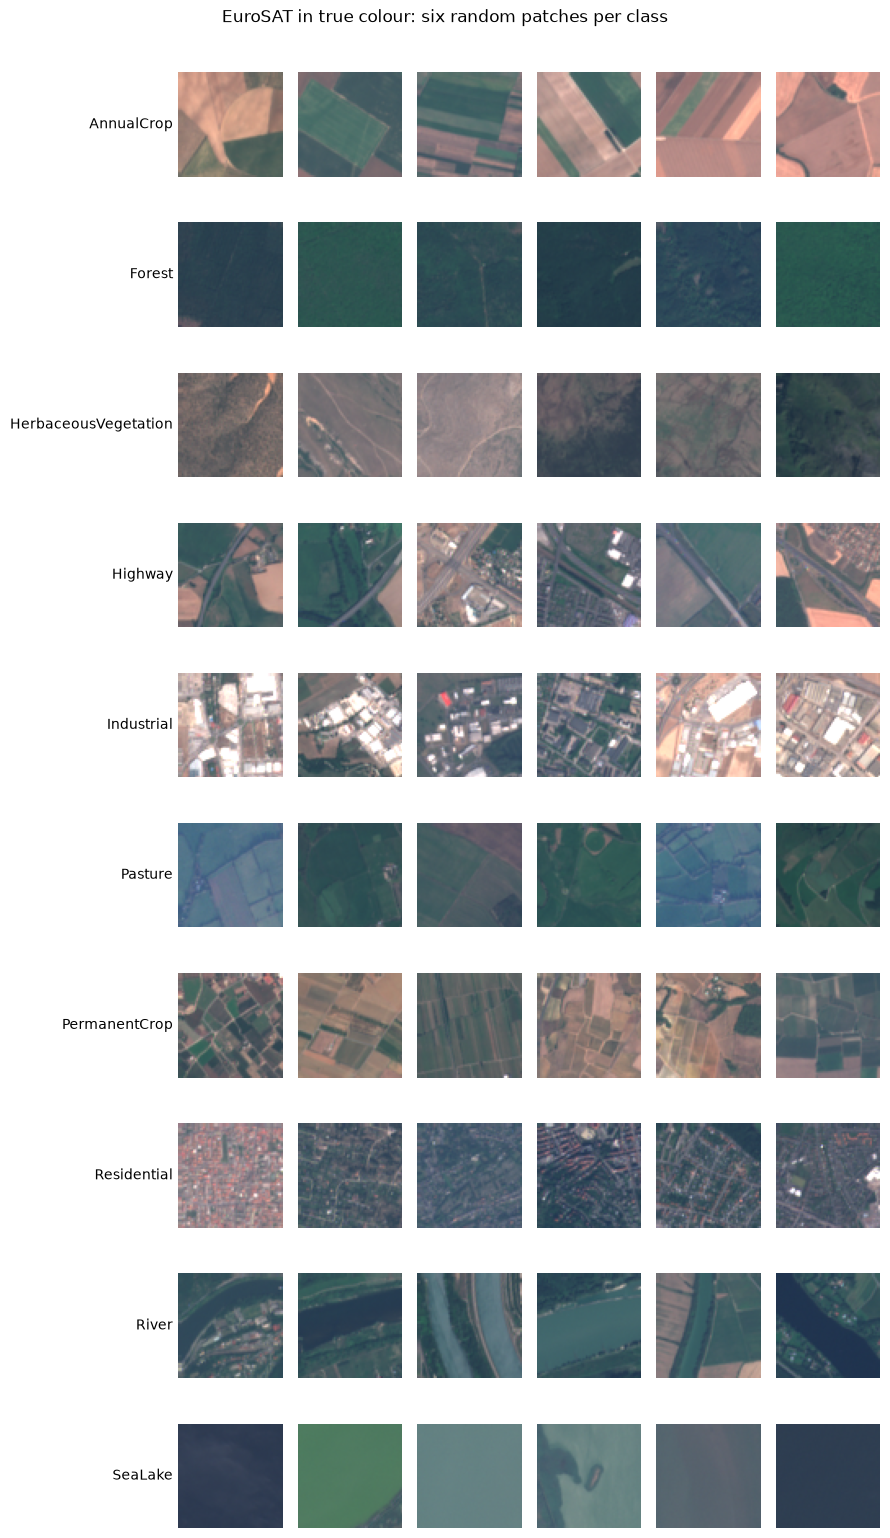

In [7]:
def composite(patch, bands=("B04", "B03", "B02"), gain=3.5):
    # Stack three bands into a displayable RGB image with values in [0, 1].
    rgb = np.stack([patch[B[b]] for b in bands], axis=-1) * gain
    return np.clip(rgb, 0, 1) ** 0.9


rng = np.random.default_rng(SEED)
N_SHOW = 6
fig, axes = plt.subplots(len(CLASSES), N_SHOW, figsize=(N_SHOW * 1.5, len(CLASSES) * 1.55))
for r, cls in enumerate(CLASSES):
    idx = rng.choice(np.where(y == r)[0], N_SHOW, replace=False)
    for c, i in enumerate(idx):
        ax = axes[r, c]
        ax.imshow(composite(X[i]))
        clean_axes(ax)
        for s in ax.spines.values():
            s.set_visible(False)
    axes[r, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=10)
fig.suptitle("EuroSAT in true colour: six random patches per class", y=1.0, fontsize=12)
plt.tight_layout()
plt.show()

Forests and lakes are easy to spot; *Pasture* and *HerbaceousVegetation* look almost the same, and a *Highway* patch is mostly fields with a thin grey line.

## Seeing beyond the visible

Other band combinations reveal more: in **false colour** (B08, B04, B03) vegetation glows red, in the **SWIR composite** (B12, B08, B04) vegetation turns green and water black.

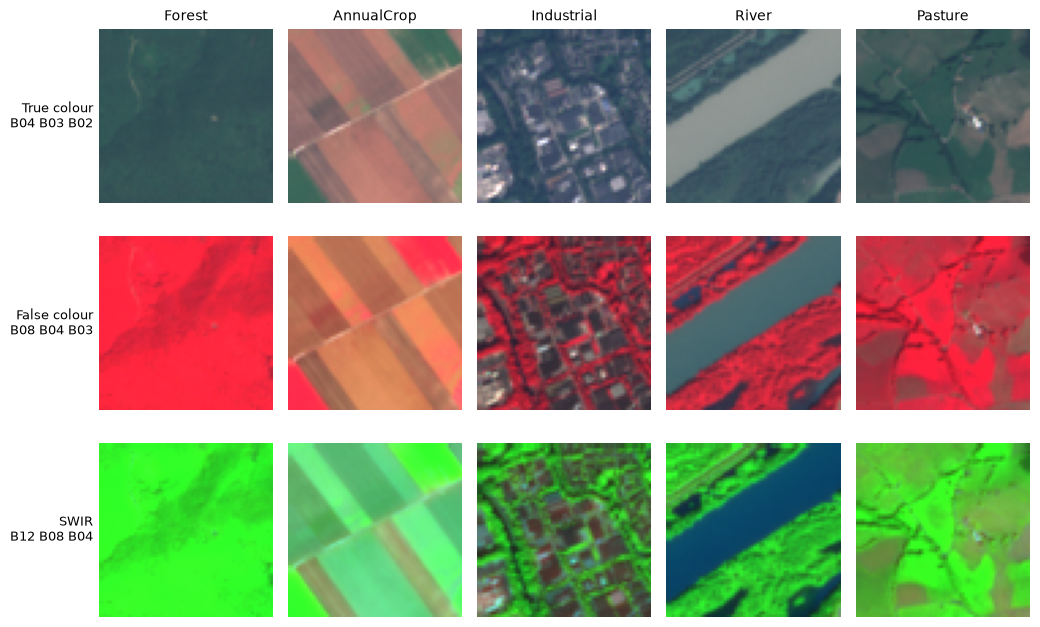

In [8]:
VIEWS = [
    ("True colour\nB04 B03 B02", ("B04", "B03", "B02"), 3.5),
    ("False colour\nB08 B04 B03", ("B08", "B04", "B03"), 2.5),
    ("SWIR\nB12 B08 B04", ("B12", "B08", "B04"), 2.5),
]
show_classes = [c for c in ["Forest", "AnnualCrop", "Industrial", "River", "Pasture"] if c in CLASSES]
rng = np.random.default_rng(1)

fig, axes = plt.subplots(len(VIEWS), len(show_classes), figsize=(len(show_classes) * 2.1, len(VIEWS) * 2.2))
for c, cls in enumerate(show_classes):
    i = rng.choice(np.where(y == CLASSES.index(cls))[0])
    for r, (title, bands, gain) in enumerate(VIEWS):
        ax = axes[r, c]
        ax.imshow(composite(X[i], bands, gain))
        clean_axes(ax)
        if r == 0:
            ax.set_title(cls, fontsize=10)
        if c == 0:
            ax.set_ylabel(title, rotation=0, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## Spectral signatures

The median reflectance of a class in each band is its **spectral signature**. Note the **red edge** (680-750 nm), where vegetation reflectance jumps; **water**, dark everywhere; and the **dip at 945 nm** (B09), caused by water vapour in the atmosphere, not by the ground. The shading covers the middle 50% of patches.

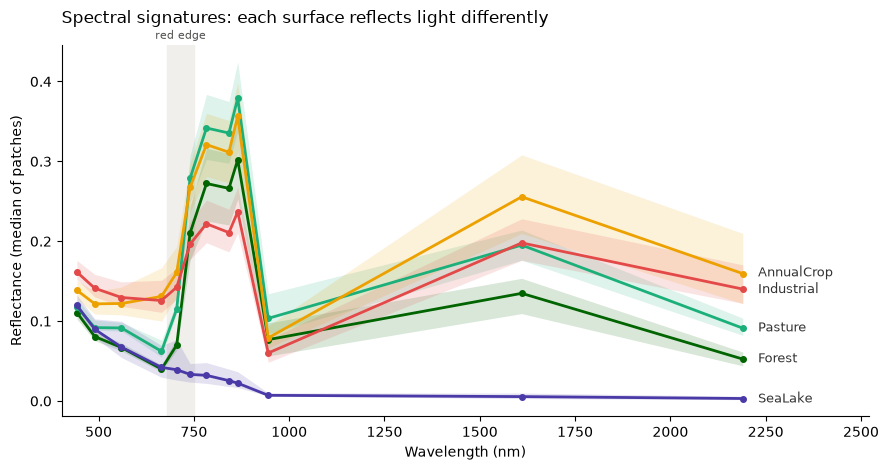

In [9]:
order = sorted([i for i in range(13) if BAND_NAMES[i] != "B10"], key=lambda i: BANDS[i][1])
wl = np.array([BANDS[i][1] for i in order])
patch_means = X.mean(axis=(2, 3))                    # (N, 13): average reflectance of each patch

sig_classes = [c for c in ["Forest", "Pasture", "AnnualCrop", "Industrial", "SeaLake"] if c in CLASSES]
fig, ax = plt.subplots(figsize=(9, 4.8))
ends = []
for cls in sig_classes:
    m = patch_means[y == CLASSES.index(cls)][:, order]
    q25, med, q75 = np.percentile(m, [25, 50, 75], axis=0)
    col = CLASS_COLORS[cls]
    ax.fill_between(wl, q25, q75, color=col, alpha=0.15, linewidth=0)
    ax.plot(wl, med, color=col, linewidth=2, marker="o", markersize=4)
    ends.append(med[-1])

ax.axvspan(680, 750, color="#f0efec", zorder=0)
ax.text(715, 1.01, "red edge", ha="center", va="bottom", fontsize=8, color="#52514e",
        transform=ax.get_xaxis_transform())
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance (median of patches)")
ax.set_title("Spectral signatures: each surface reflects light differently", loc="left", pad=16)
ax.set_xlim(wl[0] - 40, wl[-1] + 330)
label_line_ends(ax, wl[-1] + 40, ends, sig_classes)
plt.tight_layout()
plt.show()

## Spectral indices

An **index** combines two bands into one number between -1 and +1, $(A - B)/(A + B)$:

| Index | Formula | High values mean |
|---|---|---|
| **NDVI** | (NIR - Red) / (NIR + Red) | dense, healthy plants |
| **NDWI** | (Green - NIR) / (Green + NIR) | open water |
| **NDBI** | (SWIR - NIR) / (SWIR + NIR) | roofs, roads, bare ground |

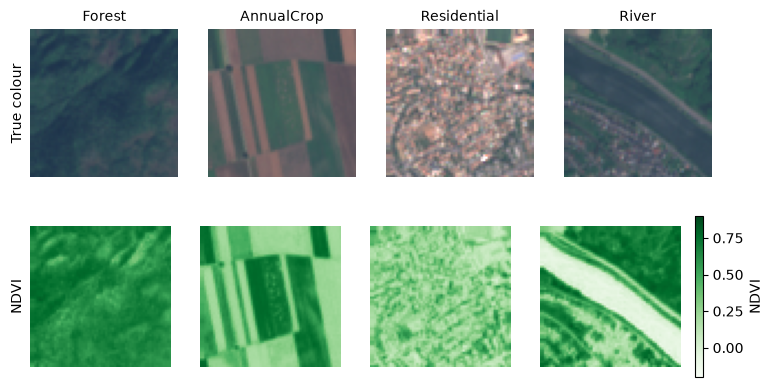

In [10]:
def norm_diff(a, b):
    return (a - b) / (a + b + 1e-6)


ndvi = norm_diff(X[:, B["B08"]], X[:, B["B04"]])    # (N, 64, 64) maps
ndwi = norm_diff(X[:, B["B03"]], X[:, B["B08"]])
ndbi = norm_diff(X[:, B["B11"]], X[:, B["B08"]])

# Left: what NDVI looks like inside a few patches.
rng = np.random.default_rng(3)
demo = [c for c in ["Forest", "AnnualCrop", "Residential", "River"] if c in CLASSES]
fig, axes = plt.subplots(2, len(demo), figsize=(len(demo) * 2.2, 4.6))
for c, cls in enumerate(demo):
    i = rng.choice(np.where(y == CLASSES.index(cls))[0])
    axes[0, c].imshow(composite(X[i]))
    axes[0, c].set_title(cls, fontsize=10)
    im = axes[1, c].imshow(ndvi[i], cmap="Greens", vmin=-0.2, vmax=0.9)
    for ax in axes[:, c]:
        clean_axes(ax)
axes[0, 0].set_ylabel("True colour")
axes[1, 0].set_ylabel("NDVI")
fig.colorbar(im, ax=axes[1, :], fraction=0.025, pad=0.02, label="NDVI")
plt.show()

## Turning a patch into features

Random Forest and SVM do not take images, they take a **row of numbers per patch** (a *feature vector*). Ours has 29: the **mean** and **standard deviation** of each of the 13 bands, plus the mean **NDVI, NDWI and NDBI**. The layout of the pixels, shapes and lines, is lost here; the CNN will use it.

In [11]:
FEATURE_NAMES = ([f"mean {b}" for b in BAND_NAMES] + [f"std {b}" for b in BAND_NAMES]
                 + ["NDVI", "NDWI", "NDBI"])
features = np.concatenate([
    X.mean(axis=(2, 3)),
    X.std(axis=(2, 3)),
    np.stack([ndvi.mean(axis=(1, 2)), ndwi.mean(axis=(1, 2)), ndbi.mean(axis=(1, 2))], axis=1),
], axis=1)

print(f"Feature table: {features.shape[0]} rows (patches) x {features.shape[1]} columns (features)\n")
print("First patch, first eight features:")
for name, v in zip(FEATURE_NAMES[:8], features[0, :8]):
    print(f"  {name:<10} {v:.4f}")

Feature table: 4000 rows (patches) x 29 columns (features)

First patch, first eight features:
  mean B01   0.1269
  mean B02   0.1034
  mean B03   0.0993
  mean B04   0.0774
  mean B05   0.1061
  mean B06   0.2564
  mean B07   0.3358
  mean B08   0.3131


### A map of the feature space

29 dimensions cannot be drawn, but **t-SNE** can squeeze them into two while keeping patches that are similar close together. Each dot is one patch, coloured by its true class. Tight, separate islands mean the features already tell those classes apart; mixed areas are where models will struggle.

This takes about half a minute.

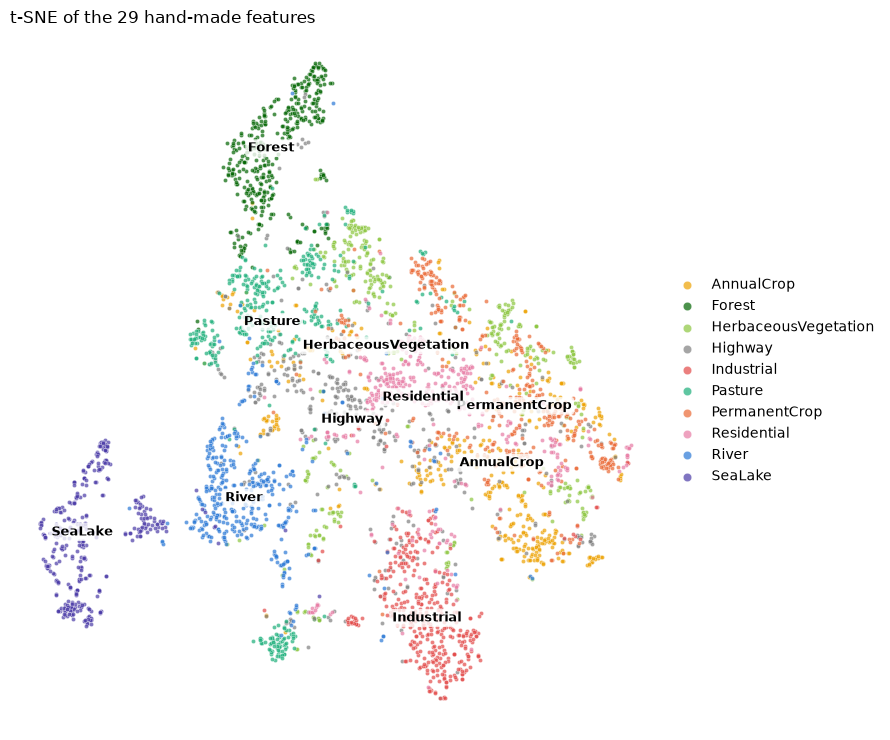

In [12]:
emb = TSNE(n_components=2, perplexity=40, random_state=SEED, init="pca").fit_transform(
    StandardScaler().fit_transform(features))

fig, ax = plt.subplots(figsize=(9, 7.5))
for c, cls in enumerate(CLASSES):
    pts = emb[y == c]
    ax.scatter(pts[:, 0], pts[:, 1], s=9, color=CLASS_COLORS[cls], alpha=0.7,
               edgecolors="white", linewidths=0.3, label=cls)
    cx, cy = np.median(pts, axis=0)
    ax.text(cx, cy, cls, fontsize=9, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
clean_axes(ax)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, markerscale=2)
ax.set_title("t-SNE of the 29 hand-made features", loc="left")
plt.tight_layout()
plt.show()

## A fair test: train and test split

A model graded on the data it learned from will look far better than it really is. So we hide a quarter of the patches before training and use them only for the final grade. The split is *stratified*: every class keeps the same share in both parts.

All three models use exactly the same split.

In [13]:
# A quarter of the patches is held back for testing.
idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.25,
                                       stratify=y, random_state=SEED)
y_train, y_test = y[idx_train], y[idx_test]
print(f"Training patches: {len(idx_train)}   Test patches: {len(idx_test)}")

RESULTS = {}   # model name -> predictions, accuracy, timing


def record(name, pred, fit_seconds):
    RESULTS[name] = dict(
        pred=pred,
        acc=accuracy_score(y_test, pred),
        f1=f1_score(y_test, pred, average=None),
        macro_f1=f1_score(y_test, pred, average="macro"),
        fit_s=fit_seconds,
    )
    r = RESULTS[name]
    print(f"{name}: accuracy {r['acc']:.1%}, macro F1 {r['macro_f1']:.3f}, trained in {fit_seconds:.1f} s")

Training patches: 3000   Test patches: 1000


## Model 1: Random Forest

A Random Forest is a group of decision trees that vote. We build one by hand in five short steps, then use the library version.

In [14]:
F_train, F_test = features[idx_train], features[idx_test]
SHORT = {"AnnualCrop": "AnnCrop", "HerbaceousVegetation": "HerbVeg", "Industrial": "Indust",
         "PermanentCrop": "PermCrop", "Residential": "Resid"}
short = [SHORT.get(c, c) for c in CLASSES]   # short class names for printing
print(f"Training table: {F_train.shape[0]} patches x {F_train.shape[1]} features")

Training table: 3000 patches x 29 features


### Step 1: one question

A tree asks questions like *"is NDVI at most 0.3?"*. A good question splits the patches into purer groups. Purity is measured with the **Gini impurity**, $1 - \sum_k p_k^2$: 0 when a group holds a single class, 0.9 for ten classes mixed evenly. Below we find the best question for NDVI, then the best question over all features: that is how a tree picks its first question.

In [15]:
def gini(labels):
    # 0 = everyone in the group has the same class; the more mixed, the higher.
    counts = np.bincount(labels)
    p = counts[counts > 0] / len(labels)
    return 1 - np.sum(p ** 2)


def best_question(values, labels):
    # Try 49 thresholds on one feature; return the one whose yes/no groups are purest.
    best_t, best_score = None, np.inf
    for t in np.quantile(values, np.linspace(0.02, 0.98, 49)):
        yes, no = labels[values <= t], labels[values > t]
        score = (len(yes) * gini(yes) + len(no) * gini(no)) / len(labels)
        if score < best_score:
            best_t, best_score = t, score
    return best_t, best_score


print(f"Gini of all training patches, before any question: {gini(y_train):.3f}\n")

# The best question about NDVI alone:
f = FEATURE_NAMES.index("NDVI")
t, score = best_question(F_train[:, f], y_train)
print(f"Best NDVI question: 'is NDVI <= {t:.2f}?'   Gini after the split: {score:.3f}")
for answer, mask in [("yes", F_train[:, f] <= t), ("no", F_train[:, f] > t)]:
    counts = np.bincount(y_train[mask], minlength=len(CLASSES))
    top = np.argsort(counts)[::-1][:3]
    print(f"  {answer:>3}: {mask.sum():4d} patches, mostly " + ", ".join(f"{CLASSES[k]} ({counts[k]})" for k in top if counts[k]))

# A real tree does not know in advance which feature to ask about: it runs the same search
# for every one of the 29 features and keeps the question that leaves the purest groups.
candidates = []
for j, name in enumerate(FEATURE_NAMES):
    thr, score = best_question(F_train[:, j], y_train)
    candidates.append((score, name, thr, int(np.sum(F_train[:, j] <= thr))))

print(f"\nThe same search over all 29 features (Gini before any question: {gini(y_train):.3f}).")
print("The five best candidates for the tree's first question:\n")
print(f"  {'question':<32}{'Gini after':>11}{'patches answering yes':>24}")
for score, name, thr, n_yes in sorted(candidates)[:5]:
    print(f"  {f'is {name} <= {thr:.4f} ?':<32}{score:>11.3f}{n_yes:>24}")
print("\n(Feature values are mean reflectance per band. A low value in the infrared bands picks out water.)")

Gini of all training patches, before any question: 0.900

Best NDVI question: 'is NDVI <= -0.01?'   Gini after the split: 0.809
  yes:  300 patches, mostly SeaLake (288), River (12)
   no: 2700 patches, mostly PermanentCrop (300), Residential (300), Highway (300)

The same search over all 29 features (Gini before any question: 0.900).
The five best candidates for the tree's first question:

  question                         Gini after   patches answering yes
  is mean B11 <= 0.0519 ?               0.804                     300
  is mean B8A <= 0.0952 ?               0.804                     300
  is mean B08 <= 0.0890 ?               0.805                     300
  is mean B06 <= 0.0910 ?               0.806                     300
  is mean B07 <= 0.0966 ?               0.806                     300

(Feature values are mean reflectance per band. A low value in the infrared bands picks out water.)


### Step 2: a tree

A **decision tree** repeats step 1 inside each group until the groups are pure. Deeper trees fit the training data better, but past some depth they only memorise it:

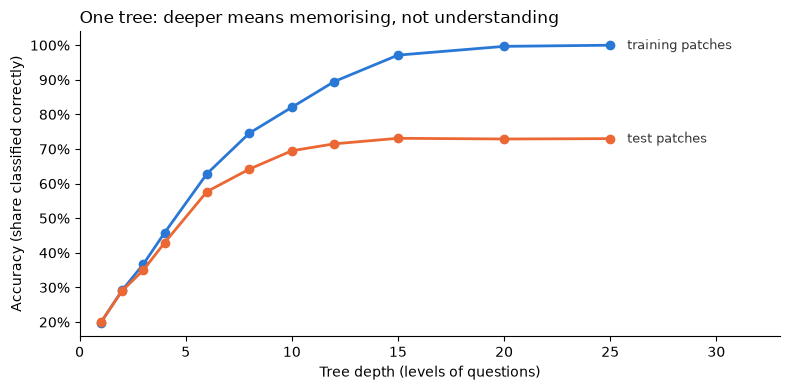

A tree with no depth limit labels 100% of the patches it learned from correctly,
but only 73% of the test patches it has never seen: it memorised the training set.


In [16]:
from sklearn.tree import DecisionTreeClassifier

depths = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, 25]
train_acc, test_acc = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(F_train, y_train)
    train_acc.append(tree.score(F_train, y_train))
    test_acc.append(tree.score(F_test, y_test))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_acc, color="#2a78d6", linewidth=2, marker="o", markersize=6)
ax.plot(depths, test_acc, color="#eb6834", linewidth=2, marker="o", markersize=6)
label_line_ends(ax, depths[-1] + 0.8, [train_acc[-1], test_acc[-1]], ["training patches", "test patches"])
ax.set_xlim(0, depths[-1] + 8)
ax.set_xlabel("Tree depth (levels of questions)")
ax.set_ylabel("Accuracy (share classified correctly)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("One tree: deeper means memorising, not understanding", loc="left")
plt.tight_layout()
plt.show()
print(f"A tree with no depth limit labels {train_acc[-1]:.0%} of the patches it learned from correctly,")
print(f"but only {test_acc[-1]:.0%} of the test patches it has never seen: it memorised the training set.")

### Step 3: many different trees

A forest grows many trees and makes them differ in two ways: each tree learns from a **bootstrap sample** (patches drawn at random, with repeats), and each question may only use a **random subset of the features**.

In [17]:
n_trees = 100
rng = np.random.default_rng(SEED)
my_forest = []
for k in range(n_trees):
    sample = rng.integers(0, len(F_train), size=len(F_train))     # bootstrap: draw with replacement
    tree = DecisionTreeClassifier(max_features="sqrt",              # random 5 features at each question
                                  random_state=k)
    tree.fit(F_train[sample], y_train[sample])
    my_forest.append(tree)

print(f"Grew {len(my_forest)} trees.")
print(f"The last tree saw {len(np.unique(sample))} distinct patches out of {len(F_train)} "
      f"({len(np.unique(sample)) / len(F_train):.0%}); the rest of its sample were repeats.")
leaves = [tree.get_n_leaves() for tree in my_forest]
print(f"Each tree keeps asking until its groups are pure, ending with {min(leaves)} to {max(leaves)} final groups (leaves).")

Grew 100 trees.
The last tree saw 1870 distinct patches out of 3000 (62%); the rest of its sample were repeats.
Each tree keeps asking until its groups are pure, ending with 371 to 423 final groups (leaves).


### Step 4: the vote

All 100 trees classify one test patch; the most common answer wins.

What the trees say about test patch 0 (true class: River):

  tree   1: Industrial
  tree   2: River
  tree   3: Industrial
  tree   4: Highway
  tree   5: River
  tree   6: SeaLake
  tree   7: River
  tree   8: SeaLake
  tree   9: Residential
  tree  10: River
  [...]
  tree  91: Industrial
  tree  92: River
  tree  93: River
  tree  94: River
  tree  95: Residential
  tree  96: River
  tree  97: Industrial
  tree  98: Industrial
  tree  99: Residential
  tree 100: Residential

Tally:
  River                   43 votes  ###########################################
  Industrial              31 votes  ###############################
  Residential             13 votes  #############
  SeaLake                  6 votes  ######
  Highway                  4 votes  ####
  HerbaceousVegetation     3 votes  ###

The forest says: River   (true class: River)


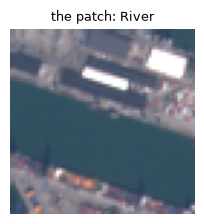

In [18]:
# Pick a test patch where the trees disagree but the majority is right: an interesting vote.
first_votes = np.stack([tree.predict(F_test) for tree in my_forest])          # (100 trees, test patches)
winner_share = np.array([np.bincount(col).max() for col in first_votes.T]) / len(my_forest)
majority = np.array([np.bincount(col).argmax() for col in first_votes.T])
interesting = np.where((majority == y_test) & (winner_share > 0.4) & (winner_share < 0.7))[0]
i = interesting[0] if len(interesting) else 0

votes = np.array([tree.predict(F_test[i:i + 1])[0] for tree in my_forest])
print(f"What the trees say about test patch {i} (true class: {CLASSES[y_test[i]]}):\n")
for k in list(range(10)) + [None] + list(range(n_trees - 10, n_trees)):
    print("  [...]" if k is None else f"  tree {k + 1:>3}: {CLASSES[votes[k]]}")

tally = np.bincount(votes, minlength=len(CLASSES))
print("\nTally:")
for k in np.argsort(tally)[::-1]:
    if tally[k]:
        print(f"  {CLASSES[k]:<22} {tally[k]:3d} votes  " + "#" * tally[k])
print(f"\nThe forest says: {CLASSES[tally.argmax()]}   (true class: {CLASSES[y_test[i]]})")

fig, ax = plt.subplots(figsize=(2.4, 2.4))
ax.imshow(composite(X[idx_test[i]]))
clean_axes(ax)
ax.set_title(f"the patch: {CLASSES[y_test[i]]}", fontsize=9)
plt.show()

### Step 5: the team vs its members

Accuracy of every single tree on the test patches, compared with their vote:

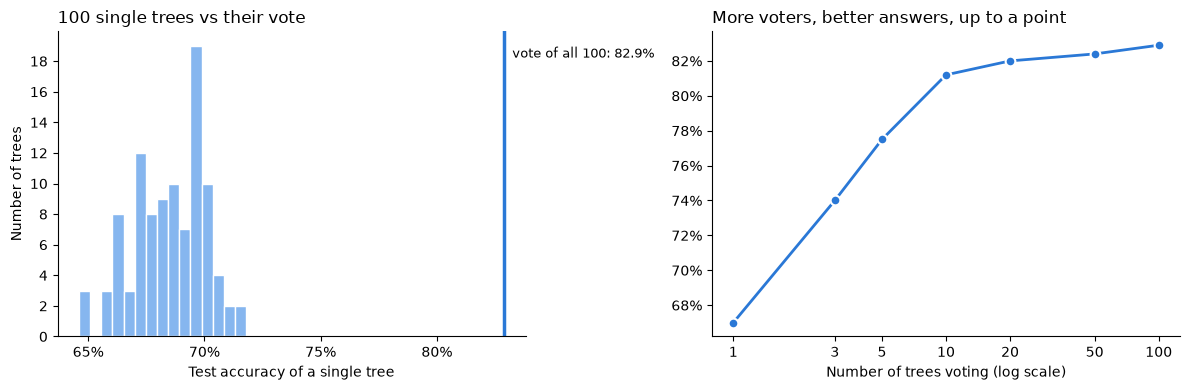

Single trees: 64.6% to 71.8% (average 68.5%). Their vote: 82.9%.


In [19]:
all_votes = first_votes          # every tree's answer for every test patch, computed in step 4
single_tree_acc = (all_votes == y_test).mean(axis=1)


def vote(votes_so_far):
    # Majority vote for every test patch (one column per patch).
    return np.array([np.bincount(col, minlength=len(CLASSES)).argmax() for col in votes_so_far.T])


forest_acc = (vote(all_votes) == y_test).mean()
sizes = [1, 3, 5, 10, 20, 50, 100]
acc_by_size = [(vote(all_votes[:n]) == y_test).mean() for n in sizes]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.hist(single_tree_acc, bins=15, color="#86b6ef", edgecolor="white")
ax.xaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.axvline(forest_acc, color="#2a78d6", linewidth=2.5)
ax.text(forest_acc, ax.get_ylim()[1] * 0.95, f"  vote of all 100: {forest_acc:.1%}", va="top", fontsize=9)
ax.set_xlabel("Test accuracy of a single tree")
ax.set_ylabel("Number of trees")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("100 single trees vs their vote", loc="left")

ax = axes[1]
ax.plot(sizes, acc_by_size, color="#2a78d6", linewidth=2, marker="o", markersize=7,
        markeredgecolor="white", markeredgewidth=1.5)
ax.set_xscale("log")
ax.set_xticks(sizes, [str(s) for s in sizes])
ax.minorticks_off()
ax.set_xlabel("Number of trees voting (log scale)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("More voters, better answers, up to a point", loc="left")
plt.tight_layout()
plt.show()
print(f"Single trees: {single_tree_acc.min():.1%} to {single_tree_acc.max():.1%} (average {single_tree_acc.mean():.1%}). "
      f"Their vote: {forest_acc:.1%}.")

Every tree alone is clearly worse than the vote: varied, imperfect voters make a strong team.

`RandomForestClassifier` does all of the above in one line. Its result differs a little from ours, because its random draws differ and it averages the trees' probabilities instead of counting votes; the idea is the same.

In [20]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)   # 100 trees, like ours
rf.fit(F_train, y_train)
print(f"Our hand-made forest: {forest_acc:.1%}")
record("Random Forest", rf.predict(F_test), time.time() - t0)

Our hand-made forest: 82.9%
Random Forest: accuracy 83.6%, macro F1 0.833, trained in 0.3 s


### What did the forest look at?

**Feature importance** measures how much each feature helped the trees split classes apart. It is one of the main reasons people like Random Forests: you can check the model's reasoning against physics.

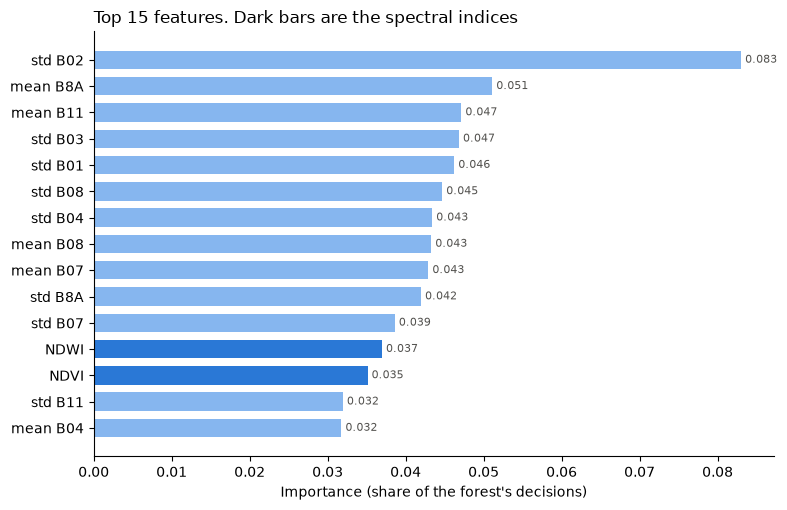

In [21]:
imp = rf.feature_importances_
top = np.argsort(imp)[::-1][:15][::-1]

fig, ax = plt.subplots(figsize=(8, 5.2))
colors = ["#2a78d6" if FEATURE_NAMES[i] in ("NDVI", "NDWI", "NDBI") else "#86b6ef" for i in top]
ax.barh(range(len(top)), imp[top], color=colors, height=0.7)
ax.set_yticks(range(len(top)), [FEATURE_NAMES[i] for i in top])
for k, i in enumerate(top):
    ax.text(imp[i], k, f" {imp[i]:.3f}", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Importance (share of the forest's decisions)")
ax.set_title("Top 15 features. Dark bars are the spectral indices", loc="left")
plt.tight_layout()
plt.show()

Texture (the standard deviations) and the invisible near- and short-wave infrared bands rank high: more reason to use all 13 bands, not an RGB photo.

## Model 2: Support Vector Machine

An SVM treats each patch as a point and draws the boundary between classes with the **widest possible margin**. The points closest to the boundary, the **support vectors**, decide where it goes.

### Step 1: a straight line, by hand

Two classes, two features. We start from any line and repeatedly move it away from points that are on the wrong side or too close to it (the *hinge loss*).

round   1: w = [+0.08, -0.07], b = +0.00   wrong side:   0   inside the street: 600
round  10: w = [+0.65, -0.55], b = +0.04   wrong side:  36   inside the street: 305
round  50: w = [+1.07, -0.83], b = -0.29   wrong side:  16   inside the street: 124
round 300: w = [+1.57, -1.17], b = -0.75   wrong side:  12   inside the street:  65


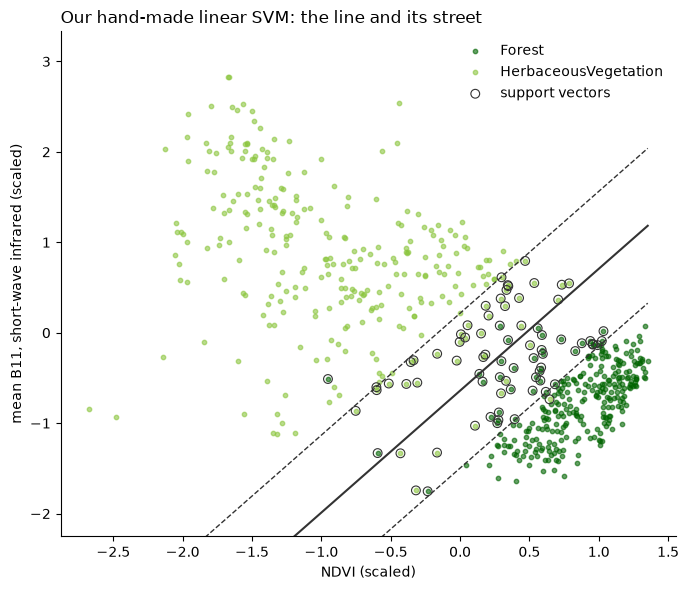

77 of 600 patches are support vectors: only they hold the line in place.
Patches on the wrong side of the line count as support vectors too, even far away:
they are mistakes that keep pulling on the line.


In [22]:
# Two classes and two features, scaled to mean 0 and standard deviation 1 (more on scaling later).
pair = [c for c in ["Forest", "HerbaceousVegetation", "Pasture", "AnnualCrop", "SeaLake"] if c in CLASSES][:2]
f_x, f_y = FEATURE_NAMES.index("NDVI"), FEATURE_NAMES.index("mean B11")
keep = np.isin(y_train, [CLASSES.index(c) for c in pair])
Z = StandardScaler().fit_transform(F_train[keep][:, [f_x, f_y]])
t = np.where(y_train[keep] == CLASSES.index(pair[0]), 1.0, -1.0)    # +1 for the first class, -1 for the second

w, b = np.zeros(2), 0.0
strength, step = 0.01, 0.1            # pull towards small weights (wide street), size of each correction
for epoch in range(1, 301):
    margin = t * (Z @ w + b)            # > 1: right side and outside the street
    bad = margin < 1                    # inside the street or on the wrong side
    w -= step * (strength * w - (t[bad, None] * Z[bad]).sum(axis=0) / len(t))
    b -= step * (-t[bad].sum() / len(t))
    if epoch in (1, 10, 50, 300):
        print(f"round {epoch:>3}: w = [{w[0]:+.2f}, {w[1]:+.2f}], b = {b:+.2f}   "
              f"wrong side: {np.sum(margin < 0):3d}   inside the street: {np.sum((margin >= 0) & (margin < 1)):3d}")

fig, ax = plt.subplots(figsize=(7, 6))
for sign, c in [(1, pair[0]), (-1, pair[1])]:
    ax.scatter(*Z[t == sign].T, s=10, color=CLASS_COLORS[c], alpha=0.6, label=c)
support = t * (Z @ w + b) <= 1
ax.scatter(*Z[support].T, s=40, facecolors="none", edgecolors="#333333", linewidths=0.8, label="support vectors")
xs = np.linspace(Z[:, 0].min(), Z[:, 0].max(), 100)
for level, style in [(0, "-"), (1, "--"), (-1, "--")]:
    ax.plot(xs, (level - b - w[0] * xs) / w[1], color="#333333", linestyle=style, linewidth=1.5 if level == 0 else 1)
ax.set_ylim(Z[:, 1].min() - 0.5, Z[:, 1].max() + 0.5)
ax.set_xlabel("NDVI (scaled)")
ax.set_ylabel("mean B11, short-wave infrared (scaled)")
ax.set_title("Our hand-made linear SVM: the line and its street", loc="left")
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()
print(f"{support.sum()} of {len(t)} patches are support vectors: only they hold the line in place.")
print("Patches on the wrong side of the line count as support vectors too, even far away:")
print("they are mistakes that keep pulling on the line.")

### Step 2: curved boundaries

A **kernel** is a measure of how similar two patches are. The **RBF kernel** $e^{-\gamma \lVert x - x_i \rVert^2}$ gives 1 for identical points and falls towards 0 as they get further apart, like a bell curve around each point. The SVM's score for a patch is a weighted sum of its similarity to each support vector, $\sum_i \alpha_i e^{-\gamma \lVert x - x_i \rVert^2} + b$, which lets the boundary bend. We let scikit-learn fit it, then recompute one score by hand.

Support vectors: 40 (circled in the plot)
Score of patch 1 by hand:         +2.2045
Score of patch 1 by scikit-learn: +2.2045
-> positive means Forest, negative HerbaceousVegetation: predicted Forest, true Forest


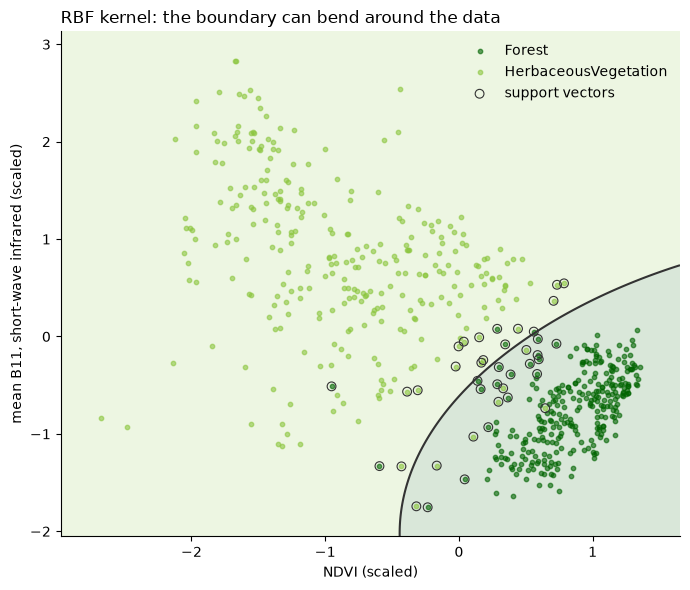

In [23]:
gamma = 0.1                                  # how fast similarity fades with distance (smaller = wider bells)
svc_rbf = SVC(kernel="rbf", gamma=gamma, C=10).fit(Z, t)

n = 1                                       # any patch of the two classes
x = Z[n]
similarity = np.exp(-gamma * ((svc_rbf.support_vectors_ - x) ** 2).sum(axis=1))   # one value per support vector
by_hand = np.sum(svc_rbf.dual_coef_[0] * similarity) + svc_rbf.intercept_[0]      # weighted sum + offset
print(f"Support vectors: {len(svc_rbf.support_vectors_)} (circled in the plot)")
print(f"Score of patch {n} by hand:         {by_hand:+.4f}")
print(f"Score of patch {n} by scikit-learn: {svc_rbf.decision_function(x[None])[0]:+.4f}")
print(f"-> positive means {pair[0]}, negative {pair[1]}: predicted {pair[0] if by_hand > 0 else pair[1]}, "
      f"true {pair[0] if t[n] > 0 else pair[1]}")

gx, gy = np.meshgrid(np.linspace(Z[:, 0].min() - 0.3, Z[:, 0].max() + 0.3, 200),
                     np.linspace(Z[:, 1].min() - 0.3, Z[:, 1].max() + 0.3, 200))
score = svc_rbf.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(gx, gy, score, levels=[-99, 0, 99], colors=[CLASS_COLORS[pair[1]], CLASS_COLORS[pair[0]]], alpha=0.15)
ax.contour(gx, gy, score, levels=[0], colors="#333333", linewidths=1.5)
for sign, c in [(1, pair[0]), (-1, pair[1])]:
    ax.scatter(*Z[t == sign].T, s=10, color=CLASS_COLORS[c], alpha=0.6, label=c)
ax.scatter(*svc_rbf.support_vectors_.T, s=40, facecolors="none", edgecolors="#333333", linewidths=0.8,
           label="support vectors")
ax.set_xlabel("NDVI (scaled)")
ax.set_ylabel("mean B11, short-wave infrared (scaled)")
ax.set_title("RBF kernel: the boundary can bend around the data", loc="left")
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()

### Step 3: ten classes, and scaling

For ten classes scikit-learn trains one SVM per pair of classes (45) and lets them vote. An SVM measures distances, so all features must be on the same scale. Compare with and without scaling:

In [24]:
n = len(CLASSES)
print(f"{n} classes -> {n * (n - 1) // 2} two-class SVMs, voting\n")

svm_raw = SVC(kernel="rbf", C=10, gamma="scale").fit(F_train, y_train)
print(f"SVM without scaling: accuracy {accuracy_score(y_test, svm_raw.predict(F_test)):.1%}")

t0 = time.time()
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale"))
svm.fit(F_train, y_train)
record("SVM", svm.predict(F_test), time.time() - t0)

10 classes -> 45 two-class SVMs, voting

SVM without scaling: accuracy 82.4%
SVM: accuracy 88.7%, macro F1 0.884, trained in 0.2 s


Scaling is worth several points here. A Random Forest does not need it: each question looks at one feature at a time.

## Model 3: Convolutional Neural Network

A CNN gets the raw patch (13 bands x 64 x 64 pixels) and learns its own features. It is built from convolutions, ReLU, pooling and learning by small steps.

### Step 1: a convolution, by hand

A 3 x 3 filter slides over the image; each output pixel is the sum of 9 pixels times 9 weights.

3x3 pixels under the filter (reflectance):
 [[0.138 0.162 0.193]
 [0.112 0.121 0.144]
 [0.12  0.115 0.114]]

filter weights ('vertical edges'):
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]

pixel x weight:
 [[-0.138  0.     0.193]
 [-0.224  0.     0.289]
 [-0.12   0.     0.114]]

sum = +0.1139  -> one pixel of the feature map


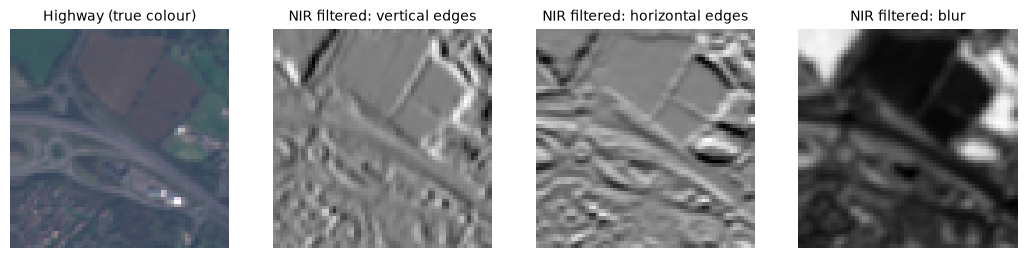

In [25]:
def convolve(image, kernel):
    # Slide a 3x3 kernel over the image; each output pixel = sum of (9 pixels x 9 weights).
    out = np.zeros((image.shape[0] - 2, image.shape[1] - 2))
    for r in range(out.shape[0]):
        for c in range(out.shape[1]):
            out[r, c] = np.sum(image[r:r + 3, c:c + 3] * kernel)
    return out


KERNELS = {
    "vertical edges":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float),
    "horizontal edges": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float),
    "blur":             np.full((3, 3), 1 / 9),
}

demo_class = [c for c in ["Highway", "River", "Industrial", "Forest"] if c in CLASSES][0]
k = idx_train[np.where(y_train == CLASSES.index(demo_class))[0][0]]
nir = X[k, B["B08"]]

# One output pixel worked out in full:
r, c = 30, 30
window = nir[r:r + 3, c:c + 3]
kern = KERNELS["vertical edges"]
print("3x3 pixels under the filter (reflectance):\n", np.round(window, 3))
print("\nfilter weights ('vertical edges'):\n", kern.astype(int))
print("\npixel x weight:\n", np.round(window * kern, 3))
print(f"\nsum = {np.sum(window * kern):+.4f}  -> one pixel of the feature map")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
axes[0].imshow(composite(X[k]))
axes[0].set_title(f"{demo_class} (true colour)", fontsize=10)
for ax, (name, kernel) in zip(axes[1:], KERNELS.items()):
    ax.imshow(convolve(nir, kernel), cmap="gray")
    ax.set_title(f"NIR filtered: {name}", fontsize=10)
clean_axes(axes)
plt.show()

In a CNN the filter weights are not written by hand: they are learned.

### Step 2: ReLU and pooling

**ReLU** sets negative values to 0; **max pooling** keeps the largest value of each 2 x 2 block, halving the image.

In [26]:
fmap = np.array([[ 1.2, -0.5,  0.3,  2.0],
                 [-1.0,  0.8, -0.2,  0.1],
                 [ 0.4, -2.2,  1.5, -0.3],
                 [ 0.9,  0.0, -0.7,  0.6]])
relu = np.maximum(fmap, 0)
pooled = relu.reshape(2, 2, 2, 2).max(axis=(1, 3))     # largest value in each 2x2 block
print("feature map:\n", fmap)
print("\nafter ReLU (negatives -> 0):\n", relu)
print("\nafter 2x2 max pooling (4x4 -> 2x2):\n", pooled)

feature map:
 [[ 1.2 -0.5  0.3  2. ]
 [-1.   0.8 -0.2  0.1]
 [ 0.4 -2.2  1.5 -0.3]
 [ 0.9  0.  -0.7  0.6]]

after ReLU (negatives -> 0):
 [[1.2 0.  0.3 2. ]
 [0.  0.8 0.  0.1]
 [0.4 0.  1.5 0. ]
 [0.9 0.  0.  0.6]]

after 2x2 max pooling (4x4 -> 2x2):
 [[1.2 2. ]
 [0.9 1.5]]


### Step 3: the network

**This cell prepares the input.** Each band is normalised to mean 0 and standard deviation 1 using the training patches, the CNN version of the scaling we gave the SVM, and the patches become a PyTorch tensor.

In [27]:
torch.manual_seed(SEED)

band_mean = X[idx_train].mean(axis=(0, 2, 3), keepdims=True)    # one mean per band
band_std = X[idx_train].std(axis=(0, 2, 3), keepdims=True)      # one spread per band
Xn = torch.from_numpy((X - band_mean) / band_std)               # all patches, normalised
yt = torch.from_numpy(y).long()                                 # their class numbers
print(f"Input tensor: {tuple(Xn.shape)} = patches x bands x height x width")

Input tensor: (4000, 13, 64, 64) = patches x bands x height x width


**This cell defines the network.** `block` is one unit of what you saw in steps 1 and 2: convolution, ReLU, convolution, ReLU, pooling. `SmallCNN` stacks three blocks (the *features* part) and ends with a *head* that averages each feature map and turns the result into one score per class. Nothing is trained yet.

In [28]:
def block(c_in, c_out):
    # One unit: two 3x3 convolutions, each followed by ReLU, then 2x2 max pooling (halves the size).
    # BatchNorm rescales the values between layers, which helps training; it does not change the idea.
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.MaxPool2d(2),
    )


class SmallCNN(nn.Module):
    def __init__(self, n_bands=13, n_classes=len(CLASSES), w=SETTINGS["cnn_width"]):
        super().__init__()
        # Features: three blocks, w -> 2w -> 4w filters, image 64 -> 32 -> 16 -> 8 pixels.
        self.features = nn.Sequential(block(n_bands, w), block(w, 2 * w), block(2 * w, 4 * w))
        # Head: average each feature map to one number, then one score per class.
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
                                  nn.Linear(4 * w, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


net = SmallCNN().to(DEVICE)
print(f"Numbers to learn (filter weights etc.): {sum(p.numel() for p in net.parameters()):,}")
print(f"First layer: {net.features[0][0].weight.shape[0]} filters, each 13 bands x 3 x 3")

Numbers to learn (filter weights etc.): 292,074
First layer: 32 filters, each 13 bands x 3 x 3


**This cell sends one patch through the untrained network** and prints the size of the data after each stage, then the class probabilities (*softmax* turns the scores into probabilities that add up to 1).

In [29]:
net.eval()
x = Xn[idx_train[:1]].to(DEVICE)                     # one patch
print(f"{'input patch':<26} {tuple(x.shape)}")
with torch.no_grad():
    for n_block, blk in enumerate(net.features, start=1):
        x = blk(x)
        print(f"{f'after block {n_block}':<26} {tuple(x.shape)}   {x.shape[1]} feature maps of {x.shape[2]} x {x.shape[3]}")
    x = net.head[1](net.head[0](x))                  # average each map, flatten
    print(f"{'average of each map':<26} {tuple(x.shape)}")
    scores = net.head[3](x)                          # final layer: one score per class
    print(f"{'one score per class':<26} {tuple(scores.shape)}")
    prob = scores.softmax(1)[0].cpu().numpy()

print("\nUntrained network, top guesses for this patch:")
for c_i in np.argsort(prob)[::-1][:4]:
    print(f"  {CLASSES[c_i]:<22} {prob[c_i]:.1%}")

input patch                (1, 13, 64, 64)
after block 1              (1, 32, 32, 32)   32 feature maps of 32 x 32
after block 2              (1, 64, 16, 16)   64 feature maps of 16 x 16
after block 3              (1, 128, 8, 8)   128 feature maps of 8 x 8
average of each map        (1, 128)
one score per class        (1, 10)

Untrained network, top guesses for this patch:
  HerbaceousVegetation   10.8%
  Residential            10.7%
  SeaLake                10.4%
  AnnualCrop             10.2%


Untrained, it gives every class roughly the same probability.

### Step 4: learning, one step at a time

**This cell trains for five steps on one batch of 64 patches.** Each step computes the **loss** (how wrong the network is, $-\log p_\text{true}$), the **gradient** (which way each weight should move) and moves the weights a little. The printout follows the loss and one single filter weight.

In [30]:
net.train()
optimizer = torch.optim.SGD(net.parameters(), lr=0.05)
batch = idx_train[:64]
xb, yb = Xn[batch].to(DEVICE), yt[batch].to(DEVICE)
one_weight = net.features[0][0].weight          # first layer filters; we follow a single number of it

for step in range(1, 6):
    scores = net(xb)
    loss = F.cross_entropy(scores, yb)          # 1. how wrong? (average of -log p_true over the batch)
    optimizer.zero_grad()
    loss.backward()                             # 2. which way should every number move?
    before = one_weight[0, 0, 0, 0].item()
    grad = one_weight.grad[0, 0, 0, 0].item()
    optimizer.step()                            # 3. take a small step that way
    p_true = scores.softmax(1)[0, yb[0]].item()
    print(f"step {step}: loss {loss.item():.3f}   p(true class) for patch 0: {p_true:.1%}   "
          f"one filter number: {before:+.4f} -> {one_weight[0, 0, 0, 0].item():+.4f} (gradient {grad:+.4f})")

step 1: loss 2.382   p(true class) for patch 0: 11.7%   one filter number: +0.0707 -> +0.0689 (gradient +0.0359)
step 2: loss 1.856   p(true class) for patch 0: 32.6%   one filter number: +0.0689 -> +0.0710 (gradient -0.0427)
step 3: loss 1.610   p(true class) for patch 0: 71.0%   one filter number: +0.0710 -> +0.0718 (gradient -0.0159)
step 4: loss 1.378   p(true class) for patch 0: 90.6%   one filter number: +0.0718 -> +0.0716 (gradient +0.0037)
step 5: loss 1.225   p(true class) for patch 0: 88.1%   one filter number: +0.0716 -> +0.0729 (gradient -0.0256)


### Step 5: full training

The same loop over the whole training set, repeated for many *epochs*, with the AdamW optimiser.

**This cell only defines three helpers**: `augment` randomly flips and rotates a batch, `predict` returns class probabilities, and `train_cnn` is the step-4 loop run over all batches and epochs.

In [31]:
def augment(xb):
    # Random flips and 90 degree rotations, applied to a whole batch.
    if torch.rand(1) < 0.5:
        xb = xb.flip(-1)
    if torch.rand(1) < 0.5:
        xb = xb.flip(-2)
    return torch.rot90(xb, int(torch.randint(0, 4, (1,))), dims=(-2, -1))


def predict(model, idx, batch=512):
    # Class probabilities for the given patches.
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, len(idx), batch):
            out.append(model(Xn[idx[s:s + batch]].to(DEVICE)).softmax(1).cpu())
    return torch.cat(out).numpy()


def train_cnn(train_idx, epochs, eval_idx=None, verbose=True, batch=64):
    model = SmallCNN().to(DEVICE)                                       # a fresh, untrained network
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, epochs=epochs,   # step size: up, then down
                                                steps_per_epoch=int(np.ceil(len(train_idx) / batch)))
    history = []
    for ep in range(epochs):                                            # one epoch = one pass over all patches
        model.train()
        perm = np.random.default_rng(SEED + ep).permutation(train_idx)  # shuffle, then cut into batches
        losses = []
        for s in range(0, len(perm), batch):
            bi = perm[s:s + batch]
            xb, yb = augment(Xn[bi]).to(DEVICE), yt[bi].to(DEVICE)
            loss = F.cross_entropy(model(xb), yb)    # 1. how wrong?
            opt.zero_grad()
            loss.backward()                          # 2. which way?
            opt.step()                               # 3. small step
            sched.step()
            losses.append(loss.item())
        row = {"epoch": ep + 1, "train_loss": float(np.mean(losses))}
        if eval_idx is not None:                                        # grade on the test patches, for the plot
            row["test_acc"] = accuracy_score(y[eval_idx], predict(model, eval_idx).argmax(1))
        history.append(row)
        if verbose and (ep == 0 or (ep + 1) % 5 == 0):
            print(f"epoch {ep + 1:>3}  loss {row['train_loss']:.3f}"
                  + (f"  test accuracy {row['test_acc']:.1%}" if "test_acc" in row else ""))
    return model, history

**This cell runs the training** and prints the loss and test accuracy every few epochs.

In [32]:
t0 = time.time()
cnn, history = train_cnn(idx_train, SETTINGS["cnn_epochs"], eval_idx=idx_test)
cnn_fit_s = time.time() - t0
cnn_proba = predict(cnn, idx_test)
record("CNN", cnn_proba.argmax(1), cnn_fit_s)

epoch   1  loss 1.529  test accuracy 67.1%
epoch   5  loss 0.567  test accuracy 82.3%
epoch  10  loss 0.374  test accuracy 88.9%
epoch  15  loss 0.240  test accuracy 90.8%
epoch  20  loss 0.138  test accuracy 95.3%
epoch  25  loss 0.109  test accuracy 96.2%
CNN: accuracy 96.2%, macro F1 0.962, trained in 23.7 s


### Watching it learn

The loss measures how wrong the network is on training data; it should fall steadily. Test accuracy is tracked only to draw the curve. We fixed the number of epochs in advance and did not pick the "best" epoch from this curve, which would be peeking at the test set.

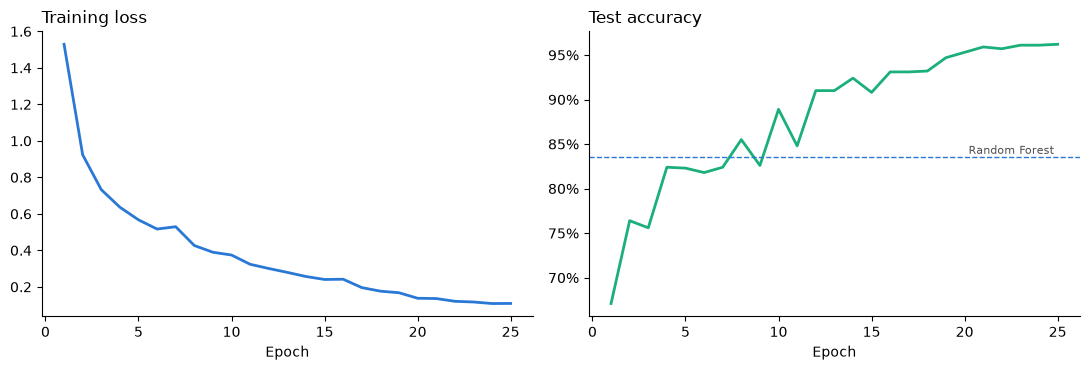

In [33]:
ep = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(ep, [h["train_loss"] for h in history], color="#2a78d6", linewidth=2)
axes[0].set_title("Training loss", loc="left")
axes[0].set_xlabel("Epoch")
axes[1].plot(ep, [h["test_acc"] for h in history], color="#1baf7a", linewidth=2)
axes[1].axhline(RESULTS["Random Forest"]["acc"], color="#2a78d6", linestyle="--", linewidth=1)
axes[1].text(ep[-1], RESULTS["Random Forest"]["acc"], "Random Forest ", ha="right", va="bottom", fontsize=8, color="#52514e")
axes[1].set_title("Test accuracy", loc="left")
axes[1].set_xlabel("Epoch")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.show()

### What did the first layer learn?

Outputs of a few trained first-layer filters for one patch.

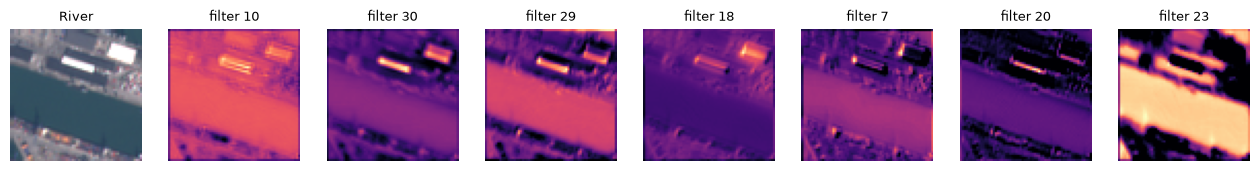

In [34]:
cnn.eval()
k = idx_test[0]
with torch.no_grad():
    maps = cnn.features[0][:3](Xn[k:k + 1].to(DEVICE))[0].cpu().numpy()   # conv -> batch norm -> ReLU
strongest = np.argsort(maps.mean(axis=(1, 2)))[::-1][:7]

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(composite(X[k]))
axes[0].set_title(CLASSES[y[k]], fontsize=9)
for ax, m in zip(axes[1:], strongest):
    ax.imshow(maps[m], cmap="magma")
    ax.set_title(f"filter {m}", fontsize=9)
clean_axes(axes)
plt.show()

## Head to head

Three models, the same test patches. **Accuracy** is the share of patches labelled correctly. **Macro F1** averages a per-class score, so a model cannot hide a weak class behind strong ones.

Model            Accuracy  Macro F1  Train time
Random Forest       83.6%     0.833       0.3 s
SVM                 88.7%     0.884       0.2 s
CNN                 96.2%     0.962      23.7 s


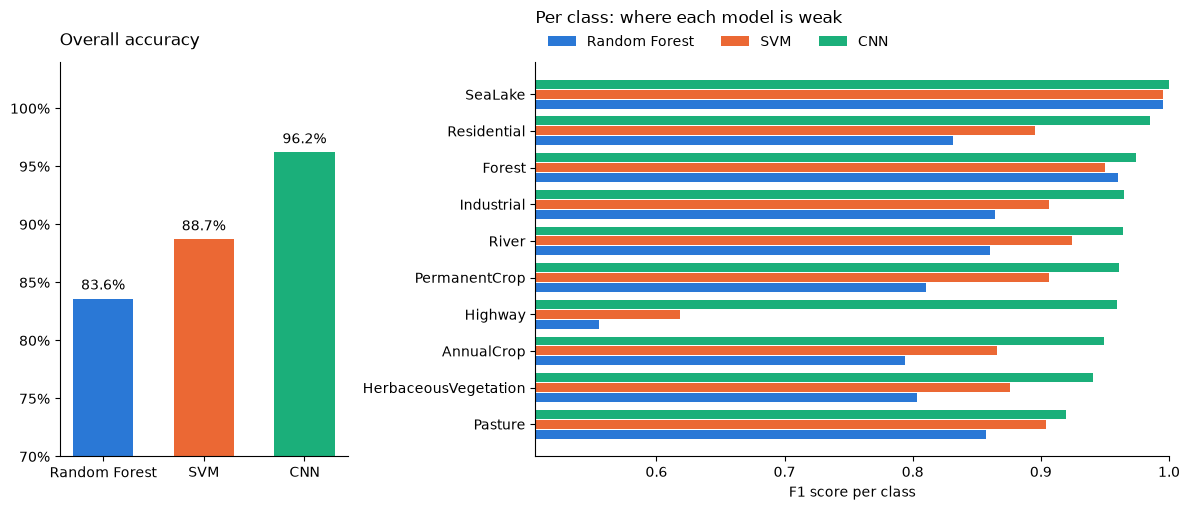

In [35]:
MODEL_COLORS = {"Random Forest": "#2a78d6", "SVM": "#eb6834", "CNN": "#1baf7a"}
names = list(RESULTS)

print(f"{'Model':<15}{'Accuracy':>10}{'Macro F1':>10}{'Train time':>12}")
for n in names:
    r = RESULTS[n]
    print(f"{n:<15}{r['acc']:>10.1%}{r['macro_f1']:>10.3f}{r['fit_s']:>10.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1, 2.2]})

ax = axes[0]
accs = [RESULTS[n]["acc"] for n in names]
ax.bar(names, accs, color=[MODEL_COLORS[n] for n in names], width=0.6)
for k, a in enumerate(accs):
    ax.text(k, a + 0.005, f"{a:.1%}", ha="center", va="bottom", fontsize=10)
ax.set_ylim(max(0, min(accs) - 0.1), 1.04)
ax.set_yticks([t for t in ax.get_yticks() if t <= 1.0])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Overall accuracy", loc="left", pad=12)

ax = axes[1]
h = 0.27
cls_sorted = np.argsort(RESULTS["CNN"]["f1"])
for k, n in enumerate(names):
    ax.barh(np.arange(len(CLASSES)) + (k - 1) * h, RESULTS[n]["f1"][cls_sorted],
            height=h * 0.9, color=MODEL_COLORS[n], label=n)
ax.set_yticks(range(len(CLASSES)), [CLASSES[c] for c in cls_sorted])
ax.set_xlim(max(0, min(RESULTS[n]["f1"].min() for n in names) - 0.05), 1.0)
ax.set_xlabel("F1 score per class")
ax.set_title("Per class: where each model is weak", loc="left", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### Confusion matrices

Rows are the true class, columns the prediction; off-diagonal cells are mix-ups. Look at **Highway**: the classic models get only about two in three right, because a road is a *shape* and our 29 numbers do not describe shapes. The CNN, which sees the pixels, gets around nine in ten.

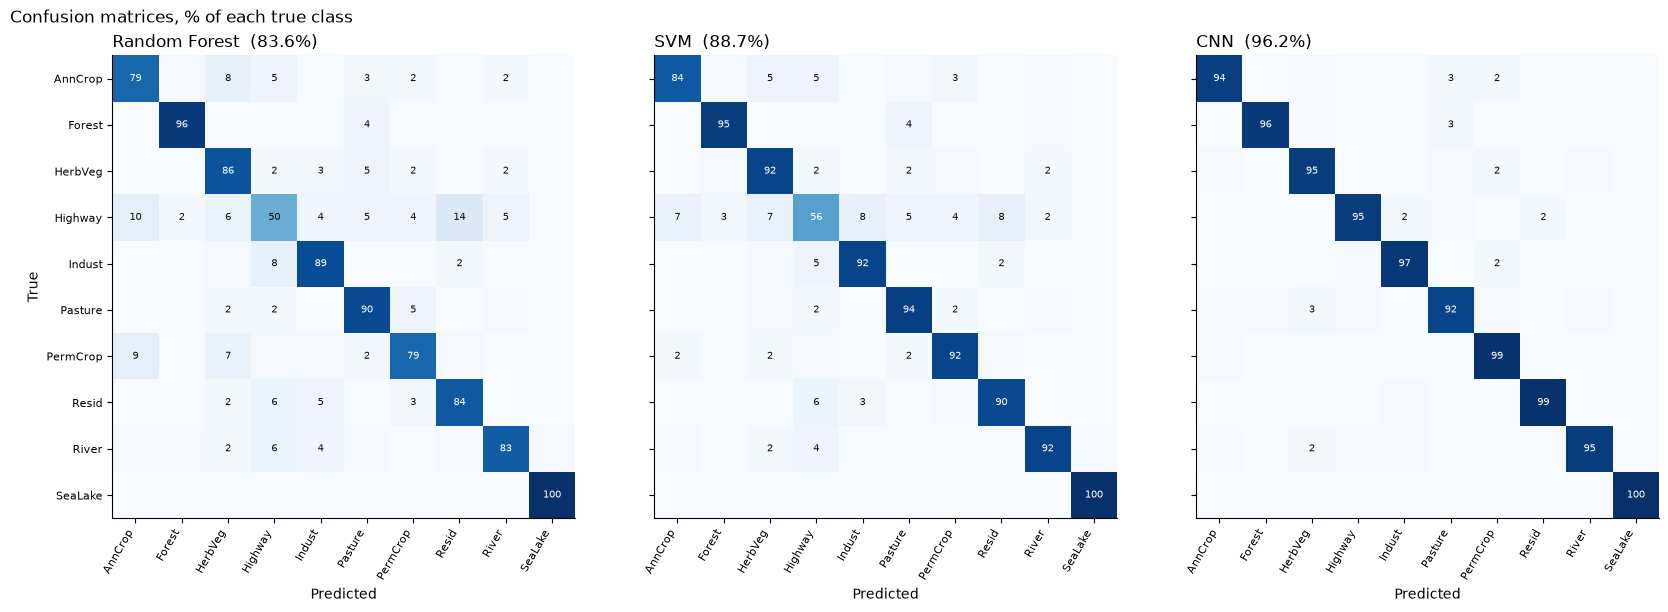

In [36]:
SHORT = {"AnnualCrop": "AnnCrop", "HerbaceousVegetation": "HerbVeg", "Industrial": "Indust",
         "PermanentCrop": "PermCrop", "Residential": "Resid"}
short = [SHORT.get(c, c) for c in CLASSES]
fig, axes = plt.subplots(1, 3, figsize=(17, 6), layout="constrained")
for ax, n in zip(axes, names):
    cm = confusion_matrix(y_test, RESULTS[n]["pred"], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if cm[i, j] >= 0.02:
                ax.text(j, i, f"{cm[i, j]:.0%}".replace("%", ""), ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > 0.5 else "#0b0b0b")
    ax.set_xticks(range(len(CLASSES)), short, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(CLASSES)), short if n == names[0] else [], fontsize=8)
    ax.set_title(f"{n}  ({RESULTS[n]['acc']:.1%})", loc="left")
    ax.set_xlabel("Predicted")
axes[0].set_ylabel("True")
fig.suptitle("Confusion matrices, % of each true class", x=0.01, ha="left", fontsize=12)
plt.show()

## Where the CNN still goes wrong

Numbers only tell part of the story. Below are test patches the CNN got wrong, with what it said and how confident it was. Many mistakes are understandable: a river that is barely a stream, a highway lost among fields, a pasture that really does look like herbaceous vegetation. Some are arguably labelling errors in the dataset itself.

The CNN got 38 of 1000 test patches wrong.


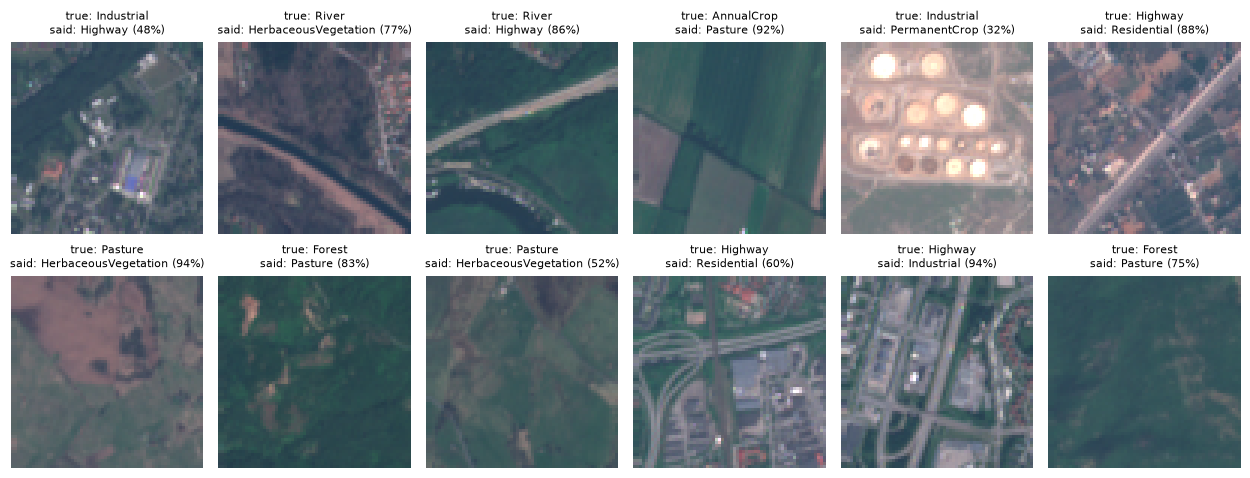

In [37]:
wrong = np.where(RESULTS["CNN"]["pred"] != y_test)[0]
print(f"The CNN got {len(wrong)} of {len(y_test)} test patches wrong.")

if len(wrong):
    rng = np.random.default_rng(SEED)
    pick = rng.choice(wrong, min(12, len(wrong)), replace=False)
    cols = 6
    rows = int(np.ceil(len(pick) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.1, rows * 2.5), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, k in zip(axes.ravel(), pick):
        i = idx_test[k]
        p = RESULTS["CNN"]["pred"][k]
        ax.imshow(composite(X[i]))
        ax.set_title(f"true: {CLASSES[y[i]]}\nsaid: {CLASSES[p]} ({cnn_proba[k, p]:.0%})", fontsize=8)
    plt.tight_layout()
    plt.show()

## Bonus: how much data does each model need?

All three models trained on 5% to 100% of the training set. This retrains the CNN five times, so it runs by itself only on a GPU; set `RUN_DATA_EXPERIMENT = True` to run it anyway.

  150 training patches: Random Forest 72.9%  SVM 74.7%  CNN 78.9%
  300 training patches: Random Forest 74.0%  SVM 77.5%  CNN 85.8%
  750 training patches: Random Forest 77.6%  SVM 82.4%  CNN 92.4%
 1500 training patches: Random Forest 80.4%  SVM 86.3%  CNN 94.0%
 3000 training patches: Random Forest 83.8%  SVM 88.7%  CNN 95.8%


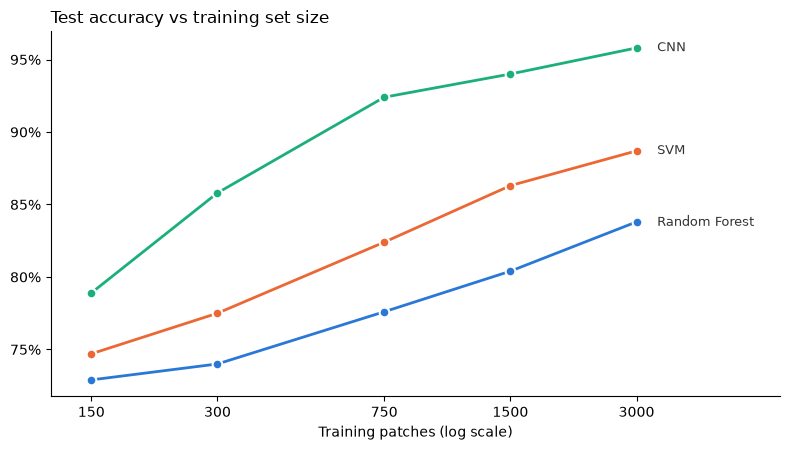

In [38]:
RUN_DATA_EXPERIMENT = SETTINGS["data_experiment"]
FRACTIONS = [0.05, 0.1, 0.25, 0.5, 1.0]

if RUN_DATA_EXPERIMENT:
    curve = {n: [] for n in MODEL_COLORS}
    for frac in FRACTIONS:
        if frac < 1.0:
            sub, _ = train_test_split(idx_train, train_size=frac, stratify=y_train, random_state=SEED)
        else:
            sub = idx_train
        curve["Random Forest"].append(accuracy_score(y_test, RandomForestClassifier(
            n_estimators=300, n_jobs=-1, random_state=SEED).fit(features[sub], y[sub]).predict(F_test)))
        curve["SVM"].append(accuracy_score(y_test, make_pipeline(StandardScaler(), SVC(
            kernel="rbf", C=10, gamma="scale")).fit(features[sub], y[sub]).predict(F_test)))
        # Small sets get more epochs so the network sees a similar number of examples.
        m, _ = train_cnn(sub, int(SETTINGS["cnn_epochs"] * min(4, 1 / np.sqrt(frac))), verbose=False)
        curve["CNN"].append(accuracy_score(y_test, predict(m, idx_test).argmax(1)))
        print(f"{len(sub):>5} training patches: " + "  ".join(f"{n} {curve[n][-1]:.1%}" for n in curve))

    sizes = [int(round(f * len(idx_train))) for f in FRACTIONS]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    for n, accs in curve.items():
        ax.plot(sizes, accs, color=MODEL_COLORS[n], linewidth=2, marker="o", markersize=7,
                markeredgecolor="white", markeredgewidth=1.5)
    ax.set_xscale("log")
    ax.set_xticks(sizes, [str(s) for s in sizes])
    ax.minorticks_off()
    ax.set_xlim(sizes[0] * 0.8, sizes[-1] * 2.2)
    ax.set_xlabel("Training patches (log scale)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title("Test accuracy vs training set size", loc="left")
    label_line_ends(ax, sizes[-1] * 1.12, [curve[n][-1] for n in curve], list(curve))
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: no GPU here. Set RUN_DATA_EXPERIMENT = True to run it anyway (30+ minutes on CPU).")

The CNN keeps up with the classic models even on very little data, helped by augmentation, and all three keep improving as data grows.

## Recap

- The **invisible bands** (red edge, NIR, SWIR) carry most of the information; **indices** like NDVI summarise it in one number.
- **Random Forest**: many trees, each on a bootstrap sample with random features, vote. The vote beats every single tree.
- **SVM**: the widest-margin boundary, set by the support vectors; curved with the RBF kernel; needs scaled inputs.
- **CNN**: learned filters, ReLU, pooling, trained by small gradient steps. It sees shapes, so it wins here, at the cost of more compute.
- Always test on data the model never saw, and look at the mistakes.

## Try it yourself

- Raise `patches_per_class` to 2,000. Which model gains the most?
- Train the CNN on the three RGB bands only. How much do the invisible bands matter?

## Next in the series

**Notebook 2: measuring forests from space**: predicting tree height in metres for every pixel, from Sentinel-2 in the **OLMOEarth** dataset.

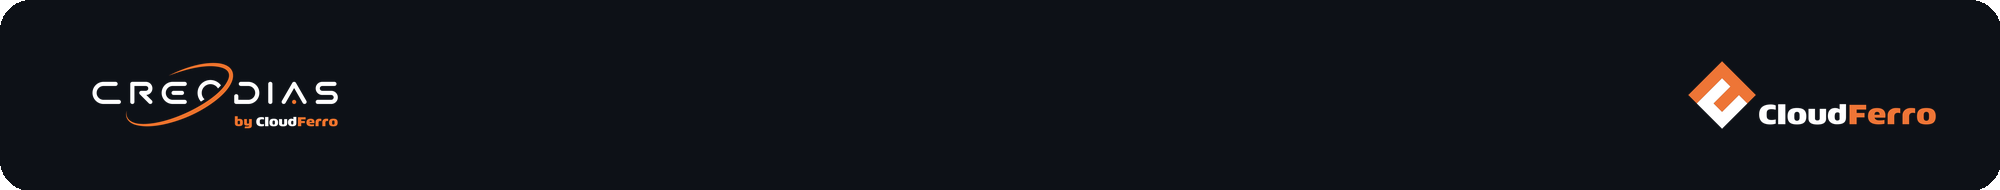

Run on [CREODIAS](https://creodias.eu), an Earth observation platform by [CloudFerro](https://cloudferro.com). The archive is mounted read only at `/eodata` on every CREODIAS virtual machine; this notebook copies the files it needs from there to local disk.
